In [1]:
import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
from collections import defaultdict, Counter

from PIL import Image,ImageFile
import albumentations as A
import matplotlib.pyplot as plt

from sklearn import model_selection
import segmentation_models_pytorch as smp

import torch
from torch import nn,optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

ImageFile.LOAD_TRUNCATED_IMAGES = True
device = 'cuda'

In [2]:
import torch
torch.cuda.empty_cache()

In [3]:
device

'cuda'

In [4]:
NUM_EPOCHS = 1
BATCH_SIZE = 24

In [5]:
from torch.utils.data import Dataset
from torchvision.transforms.v2 import Compose, PILToTensor, ToDtype, Normalize
from torchvision import transforms
import os
from PIL import Image
import pandas as pd


class MaskDataset(Dataset):
    def __init__(self, mask_dir, image_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.image_dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(img_path)

        mask_path = os.path.join(self.mask_dir, str('img_' + str(idx) + '.png'))
        mask = Image.open(mask_path)
        
        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        return {
            'image': torch.Tensor(image),
            'mask': torch.Tensor(mask)
        }

#csv_file = 'C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/train_answers.csv'
#image_dir = 'C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/train_lung_masks'
trainimgs = 'C:/Users/macar/intensive-ml-autumn/data/train_images'
masksimgs = 'C:/Users/macar/intensive-ml-autumn/data/train_lung_masks'

transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

data_train = MaskDataset(mask_dir=masksimgs, image_dir=trainimgs, transform=transform)

In [6]:
data_train[0]['mask'].shape, data_train[0]['image'].shape

(torch.Size([1, 256, 256]), torch.Size([1, 256, 256]))

In [7]:
def train(data_loader, model, criterion, optimizer):
    model.train()
    train_loss = 0
    for data in tqdm(data_loader):
        inputs = data['image']
        labels = data['mask']

        inputs = inputs.to(device, dtype=torch.float)
        labels = labels.to(device, dtype=torch.float)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        train_loss += loss.item()
        loss.backward()
        optimizer.step()

    return train_loss/len(data_loader)

In [8]:
def evaluate(data_loader, model, criterion):
    model.eval()
    eval_loss = 0
    with torch.no_grad():
        for data in tqdm(data_loader):
            inputs = data['image']
            labels = data['mask']

            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device, dtype=torch.float)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            eval_loss += loss.item()

    return eval_loss/len(data_loader)

In [9]:
from torch.utils.data import DataLoader
from torch.utils.data import random_split

train_set, valid_set = random_split(data_train, (0.80, 0.20))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE)
valid_loader = DataLoader(valid_set, batch_size=BATCH_SIZE)

In [10]:
from torch import nn
import torch
import torchvision.transforms.functional as TF


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernal_size, strides, padding):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels, num_segmentations=1, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.bottleneck = DoubleConv(
            in_channels=features[-1],
            out_channels=features[-1]*2,
            kernal_size=3,
            strides=1,
            padding=1
        )
        self.output = nn.Conv2d(
            in_channels=features[0],
            out_channels=num_segmentations,
            kernel_size=1
        )
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        in_channels_iter = in_channels
        for feature in features:
            self.downs.append(DoubleConv(
                    in_channels=in_channels_iter,
                    out_channels=feature,
                    kernal_size=3,
                    strides=1,
                    padding=1
                ))
            in_channels_iter = feature

        for feature in reversed(features):
            up = nn.Sequential(
                nn.ConvTranspose2d(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernel_size=2,
                    stride=2,
                    padding=0
                ),
                DoubleConv(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernal_size=3,
                    padding=1,
                    strides=1
                )
            )

            self.ups.append(up)

    def forward(self, x):
        skip_connections = []
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for i in range(len(self.ups)):
            x = self.ups[i][0](x) # Pass through ConvTranspose first

            skip_connection = skip_connections[i]

            # If the height and width of output tensor and skip connection
            # is not same then resize the tensor
            if x.shape != skip_connection.shape:
                x = TF.resize(x, size=skip_connection.shape[2:])

            # Concat the output tensor with skip connection
            concat_x = torch.cat((skip_connection, x), dim=1)

            # Pass the concatinated tensor through DoubleCOnv
            x = self.ups[i][1](concat_x)

        return self.output(x)

In [11]:
model = UNet(in_channels=1).to(device)

In [12]:
optimizer = torch.optim.Adam(model.parameters())
criterion = nn.MSELoss()

In [13]:
from torchsummary import summary

summary(model, (1, 256, 256), device=device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 256, 256]             576
       BatchNorm2d-2         [-1, 64, 256, 256]             128
              ReLU-3         [-1, 64, 256, 256]               0
            Conv2d-4         [-1, 64, 256, 256]          36,864
       BatchNorm2d-5         [-1, 64, 256, 256]             128
              ReLU-6         [-1, 64, 256, 256]               0
        DoubleConv-7         [-1, 64, 256, 256]               0
         MaxPool2d-8         [-1, 64, 128, 128]               0
            Conv2d-9        [-1, 128, 128, 128]          73,728
      BatchNorm2d-10        [-1, 128, 128, 128]             256
             ReLU-11        [-1, 128, 128, 128]               0
           Conv2d-12        [-1, 128, 128, 128]         147,456
      BatchNorm2d-13        [-1, 128, 128, 128]             256
             ReLU-14        [-1, 128, 1

In [14]:
for epoch in range(NUM_EPOCHS):

    train_loss = train(train_loader,
                       model,
                       criterion,
                       optimizer)
    

    val_loss = evaluate(valid_loader,
                        model,
                        criterion)

    print(f'Epoch: {epoch+1}')
    print(f'Training Loss: {train_loss}, \t Validation Loss: {val_loss}\n')

100%|██████████| 225/225 [1:06:10<00:00, 17.65s/it]

Epoch: 1
Training Loss: 0.020286029099176327, 	 Validation Loss: 0.011244128642396795


In [15]:
torch.save(model.state_dict(), 'weights.pth')   

# Смотрим результаты

## Здесь работа на валидационной

  0%|          | 0/900 [00:00<?, ?it/s]
C:\Program Files\Python\Python310\lib\site-packages\torchshow\visualization.py:388: UserWarning: Original input range is not 0-1 when using grayscale mode. Auto-rescaling it to 0-1 by default.
  warnings.warn('Original input range is not 0-1 when using grayscale mode. Auto-rescaling it to 0-1 by default.')


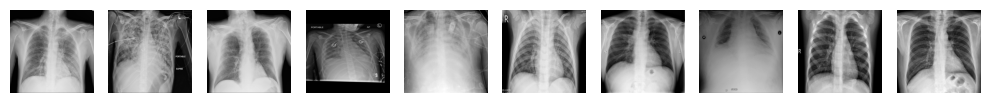

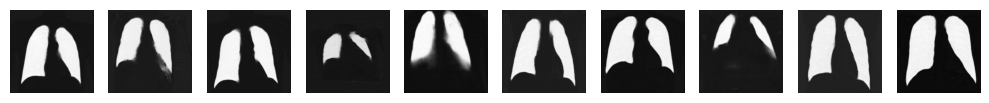

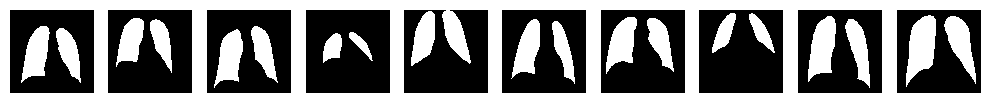

In [16]:
model.eval()
with torch.no_grad():
    for data in tqdm(train_loader):
            inputs = data['image']
            labels = data['mask']

            inputs = inputs.to(device, dtype=torch.float)

            outputs = model(inputs)
            break
import torchshow as ts

x = torch.stack([inputs[i] for i in range(10)])
y = torch.stack([outputs[i] for i in range(10)])
z = torch.stack([labels[i] for i in range(10)])
ts.show(x, nrows=1, figsize=(10, 2))
ts.show(y, nrows=1, figsize=(10, 2)) # masks from model
ts.show(z, nrows=1, figsize=(10, 2)) # given masks

## Здесь маски по картинкам из тестового сета (к ним нам маски не дали, их модель никогда не видела)

In [17]:
class MyDataset(Dataset):
    def __init__(self, dir, transform=None):
        self.dir = dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.dir, str('img_' + str(idx) + '.png'))
        print(img_path)
        image = Image.open(img_path)
        
        if self.transform:
            image = self.transform(image)

        return image

  0%|          | 0/289 [00:00<?, ?it/s]

data/test_images\img_0.png
data/test_images\img_1.png
data/test_images\img_2.png
data/test_images\img_3.png
data/test_images\img_4.png
data/test_images\img_5.png
data/test_images\img_6.png
data/test_images\img_7.png
data/test_images\img_8.png
data/test_images\img_9.png
data/test_images\img_10.png
data/test_images\img_11.png
data/test_images\img_12.png
data/test_images\img_13.png
data/test_images\img_14.png
data/test_images\img_15.png
data/test_images\img_16.png
data/test_images\img_17.png
data/test_images\img_18.png
data/test_images\img_19.png
data/test_images\img_20.png
data/test_images\img_21.png
data/test_images\img_22.png
data/test_images\img_23.png


  0%|          | 0/289 [00:00<?, ?it/s]


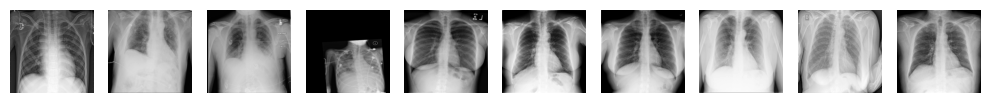

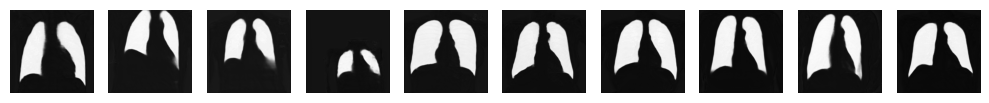

In [18]:
test_set = MyDataset('data/test_images', transform=transform)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)
model.eval()
data = []

with torch.no_grad():
    for data in tqdm(test_loader):
        inputs = data

        inputs = inputs.to(device, dtype=torch.float)

        outputs = model(inputs)
        break
        
import torchshow as ts

x = torch.stack([inputs[i] for i in range(10)])
y = torch.stack([outputs[i] for i in range(10)])
ts.show(x, nrows=1, figsize=(10, 2))  # pictures from test_images
ts.show(y, nrows=1, figsize=(10, 2))  # masks from this model